# 05 · EMT-TF expression (unconditional)
The EMT-TF step runs regardless of the gate outcome; here it is notebook **05** (Gate 3 NO-GO → 01–04 + expression). Panel gated on detectable expression, widened beyond Snail/Zeb/Twist to the FOXC/PRRX mesenchymal families. **VIM is excluded** — it is a mesenchymal marker, not a transcription factor. Shown as a **categorical overlay of thresholded expressers on a grey manifold**, not a continuous colormap.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R'
import numpy as np, pandas as pd
import scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [ ]:
# read the manifold with pseudotime (Puram branching square layout, raw X_umap)
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
t = adata.obs['t'].values; tn = (t - t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime', round(t.min(),2), '->', round(t.max(),2))

cells: 2118 | pseudotime 0.14 -> 7.21


In [ ]:
# widened EMT-TF panel gated on detectable expression. VIM excluded (marker, not a TF).
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
X = adata[:, present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
early = tn <= np.quantile(tn,1/3); late = tn >= np.quantile(tn,2/3)
rows = []
for j, g in enumerate(present):
    x = X[:, j]; rho,_ = spearmanr(tn, x); me, ml = x[early].mean(), x[late].mean()
    rows.append((g, round((x>0).mean(),3), round(me,3), round(ml,3), round(rho,3),
                 round((ml-me)/(ml+me+1e-9),3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t','end_bias']).sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.05].copy()
print('\ndetectable EMT-TFs (frac_expr>0.05):', ok.TF.tolist())
# overlay contrasts the two rho_vs_t extremes among detectable TFs; label each by the ACTUAL
# sign of its trend (do not assert 'terminus' for a TF whose rho is negative).
tf_lo = ok.iloc[0]['TF'];  rho_lo = float(ok.iloc[0]['rho_vs_t'])
tf_hi = ok.iloc[-1]['TF']; rho_hi = float(ok.iloc[-1]['rho_vs_t'])
def _trend(r): return 'terminus-trending' if r > 0.05 else ('root-trending' if r < -0.05 else 'flat')
print(f'overlay pair (rho_vs_t extremes): {tf_lo} rho={rho_lo:+.2f} ({_trend(rho_lo)}) '
      f'<-> {tf_hi} rho={rho_hi:+.2f} ({_trend(rho_hi)})')
# data-derived interpretation (never hardcode a direction): describe the spread of detectable TFs.
mx = float(ok['rho_vs_t'].abs().max())
if mx <= 0.10:
    print(f'NB: every detectable EMT-TF is pseudotime-flat (|rho|<={mx:.2f}) - a pan-tumour EMT-TF '
          f'program, not a trajectory-localized terminal EMT switch. The overlay contrasts the two '
          f'rho extremes ({tf_lo} vs {tf_hi}) only to show the (weak) spread.')
else:
    print(f'NB: detectable EMT-TFs span rho {ok["rho_vs_t"].min():+.2f} to {ok["rho_vs_t"].max():+.2f}; '
          f'the overlay contrasts the two extremes ({tf_lo} vs {tf_hi}).')

    TF  frac_expr  mean_early  mean_late  rho_vs_t  end_bias
TWIST2      0.001       0.008      0.000    -0.036    -1.000
 PRRX2      0.012       0.059      0.035    -0.010    -0.258
 FOXC2      0.002       0.007      0.001     0.000    -0.662
 FOXC1      0.002       0.012      0.006     0.004    -0.298
TWIST1      0.002       0.008      0.009     0.007     0.041
 SNAI2      0.033       0.151      0.170     0.014     0.059
 PRRX1      0.578       2.261      2.261     0.018     0.000
 SNAI1      0.083       0.305      0.330     0.039     0.040
  ZEB1      0.781       3.357      3.876     0.066     0.072
  ZEB2      0.771       2.751      3.366     0.094     0.100

detectable EMT-TFs (frac_expr>0.05): ['PRRX1', 'SNAI1', 'ZEB1', 'ZEB2']
overlay pair (rho_vs_t extremes): PRRX1 rho=+0.02 (flat) <-> ZEB2 rho=+0.09 (terminus-trending)
NB: every detectable EMT-TF is pseudotime-flat (|rho|<=0.09) - a pan-tumour EMT-TF program, not a trajectory-localized terminal EMT switch. The overlay contrast

PRRX1: 57.8% expressing; 123 shown (top decile); mean pseudotime of shown = 0.51 (all 0.51)
ZEB2: 77.1% expressing; 164 shown (top decile); mean pseudotime of shown = 0.46 (all 0.51)
saved expression.pdf


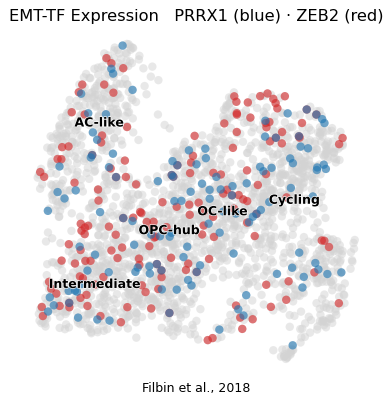

In [ ]:
# deliverable: expression.pdf — CATEGORICAL overlay of thresholded expressers on a grey manifold.
# threshold = top decile among expressing cells (so a broad factor is not washed across the manifold).
def vec(g):
    x = adata[:, g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [tf_lo, tf_hi]:
    v = vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos,0.90)) if pos.size else 0.0
sel = {g: vec(g) > thr[g] for g in [tf_lo, tf_hi]}
order = sorted([tf_lo, tf_hi], key=lambda g: -int(sel[g].sum()))
colors = {tf_lo:'tab:blue', tf_hi:'tab:red'}
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, size=180, alpha=.5, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    sc.pl.umap(adata[sel[g]].copy(), na_color=colors[g], size=180, alpha=.6,
               frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='milestones', size=180, alpha=0, legend_loc='on data',
           legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title(f'EMT-TF Expression   {tf_lo} (blue) \u00b7 {tf_hi} (red)', size=13)
ax.text(.5, -.05, 'Filbin et al., 2018', ha='center', transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig, 'expression.pdf'), bbox_inches='tight')
for g in [tf_lo, tf_hi]:
    print(f'{g}: {(vec(g)>0).mean()*100:.1f}% expressing; {int(sel[g].sum())} shown (top decile); '
          f'mean pseudotime of shown = {tn[sel[g]].mean():.2f} (all {tn.mean():.2f})')
print('saved expression.pdf')